# A SymPy Optical-Science Course, and the Quarter-Wave Plate as a Quantum Gate

## Part A: course map

Twenty notebooks from this repo, ordered so that each unit uses only what came before. Every one is
SymPy-first with numerical checks and tests.

| unit | math you need | notebooks (in order) |
|---|---|---|
| **1. Calculus 2 tools** | series, improper integrals, Taylor | [planck_quantization_taylor](planck_quantization_taylor.ipynb) · [spectra_continuous_discrete](spectra_continuous_discrete.ipynb) · [dimensions_inner_product](dimensions_inner_product.ipynb) |
| **2. Calculus 3 / vector fields** | surface integrals, Gauss's law, spherical coordinates | [thomson_vs_rutherford](thomson_vs_rutherford.ipynb) · [spherical_bessel_oscilloscope](spherical_bessel_oscilloscope.ipynb) |
| **3. Electricity & magnetism** | phasors, impedance, waves | [griffiths_impedance_reactance](griffiths_impedance_reactance.ipynb) · [wien_wave_502](wien_wave_502.ipynb) · [complex_eigen_bridge](complex_eigen_bridge.ipynb) |
| **4. Modern physics (Knight ch. 37)** | energy conservation, statistics | [nuclide_notation_loop](nuclide_notation_loop.ipynb) · [charge_to_mass_millikan](charge_to_mass_millikan.ipynb) · [neutron_decay_sympy](neutron_decay_sympy.ipynb) · [ch37_probability_sympy_stats](ch37_probability_sympy_stats.ipynb) |
| **5. Optical engineering** | eigenvectors, dispersion, design rules | [waveguide_array_eigenvectors](waveguide_array_eigenvectors.ipynb) · [pulse_moments_group_delay](pulse_moments_group_delay.ipynb) · [optics_decision_tree](optics_decision_tree.ipynb) · [photons_in_semiconductors](photons_in_semiconductors.ipynb) |
| **6. Quantum notation & QIS** | Dirac notation, unitary gates | **this notebook (Part B)** · [quantum_receivers](quantum_receivers.ipynb) · [sympy_qis_performance](sympy_qis_performance.ipynb) |
| **7. Research capstone** | complex analysis + all of the above | [zero_flip_phase_retrieval](zero_flip_phase_retrieval.ipynb) · [uav_navier_stokes](uav_navier_stokes.ipynb) |

---

## Part B: polarization *is* a qubit

A light beam's polarization lives in a 2-D complex vector space, exactly like a qubit. Write
$|H\rangle = |0\rangle$ and $|V\rangle = |1\rangle$, and the optics bench turns into a quantum circuit:

| optics | quantum information |
|---|---|
| Jones vector | state ket $\lvert\psi\rangle$ |
| wave plate | single-qubit **unitary gate** |
| polarizer + detector | projective **measurement** |
| Malus's law $\cos^2\theta$ | **Born rule** $\lvert\langle\theta\vert\psi\rangle\rvert^2$ |
| Poincaré sphere (Stokes) | **Bloch sphere** |

Module: [`dgs/polarization_qubit.py`](../dgs/polarization_qubit.py). It uses the same matrix
convention as the *code* of [`dgs/jones_calculus.py`](../dgs/jones_calculus.py), which is
checked in the tests.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from dgs import jones_calculus as jc
from dgs.polarization_qubit import (
    th, KETS, X, Y, Z, S_GATE, HADAMARD, qwp, hwp, retarder, braket, equal_up_to_phase, is_unitary,
    bloch_vector, malus_born, solid_angle_octant, pancharatnam_phase, numeric,
)

# B1. States in Dirac notation

Six special states: the ±1 points on each axis of the sphere. The circular ones are named by axis
($|{\pm i}\rangle$) rather than "right/left", because which circular state counts as "right-handed"
depends on whether you look toward the source or away from it, and textbooks disagree.

In [2]:
for k, v in KETS.items():
    s = bloch_vector(v)["stokes"]
    display(Math(rf"|{k}\rangle = " + sp.latex(v.T) + rf"^T \qquad (S_1, S_2, S_3) = {sp.latex(s)}"))
display(Math(r"\langle H|V\rangle = " + sp.latex(braket(KETS['H'], KETS['V'])) + r",\quad |\langle D|{+i}\rangle|^2 = " + sp.latex(sp.simplify(sp.Abs(braket(KETS['D'], KETS['+i']))**2))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

# B2. Wave plates are quantum gates

A retarder with fast axis at angle $\theta$ is $W(\delta,\theta) = R(-\theta)\,\mathrm{diag}(1, e^{i\delta})\,R(\theta)$.
A **quarter-wave** plate has $\delta = \pi/2$ and a **half-wave** plate has $\delta = \pi$. SymPy shows the
standard gates fall out:

In [3]:
display(Math(r"\text{QWP}(0) = " + sp.latex(qwp(0)) + r" = S \text{ (phase gate)}"))
display(Math(r"\text{HWP}(0) = " + sp.latex(hwp(0)) + r" = Z"))
display(Math(r"\text{HWP}(22.5^\circ) = " + sp.latex(sp.simplify(hwp(sp.pi/8))) + r" = H \text{ (Hadamard)}"))
display(Math(r"\text{QWP}(\theta) = " + sp.latex(sp.simplify(qwp(th)))))
print("QWP(θ) unitary for all θ:", is_unitary(qwp(th)), "   HWP(θ) unitary:", is_unitary(hwp(th)))
print("QWP(45°)|H⟩ = e^{iφ}|−i⟩ (linear → circular):", equal_up_to_phase(qwp(sp.pi/4)*KETS['H'], KETS['-i']))
print("QWP(45°)² = HWP(45°) up to phase:", equal_up_to_phase(qwp(sp.pi/4)**2, hwp(sp.pi/4)),
      "   HWP(45°)|H⟩ = |V⟩:", equal_up_to_phase(hwp(sp.pi/4)*KETS['H'], KETS['V']))
print("matches dgs.jones_calculus numerically:", all(np.allclose(np.array(qwp(sp.pi*d/180).evalf(), complex), jc.jones_matrix_qwp(d)) for d in (0, 30, 45, 90)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

QWP(θ) unitary for all θ: True    HWP(θ) unitary: True
QWP(45°)|H⟩ = e^{iφ}|−i⟩ (linear → circular): True
QWP(45°)² = HWP(45°) up to phase: True    HWP(45°)|H⟩ = |V⟩: True
matches dgs.jones_calculus numerically: True


**This is how photonic quantum computing does single-qubit gates.** A half-wave plate at 22.5° is a
Hadamard gate on a single photon's polarization. And a **quarter-wave** plate is the optics version
of the **quarter-wave** impedance transformer from the impedance notebook: in both, a quarter of a
wavelength, or a $\pi/2$ phase, is what converts one kind of state into another.

# B3. Measurement: Malus's law *is* the Born rule

In [4]:
display(Math(r"P(\text{pass}) = |\langle\theta|H\rangle|^2 = " + sp.latex(malus_born(th))))
rng = np.random.default_rng(0); thetas = np.radians([0, 30, 45, 60, 90]); n = 20_000
rows = []
for t in thetas:
    p = np.cos(t)**2; clicks = rng.binomial(1, p, n).mean()       # single photons: each passes or not
    rows.append({"polarizer angle (deg)": round(np.degrees(t)), "cos²θ": round(p, 4), f"fraction of {n} photons passed": clicks})
pd.DataFrame(rows)

<IPython.core.display.Math object>

,polarizer angle (deg),cos²θ,fraction of 20000 photons passed
0,0,1.00,1.00000
1,30,0.75,0.75210
2,45,0.50,0.50265
3,60,0.25,0.24540
4,90,0.00,0.00000


With a bright beam, $\cos^2\theta$ is a smooth intensity (Malus, 1809). With **single photons**, each
photon either passes or doesn't, and $\cos^2\theta$ is the *probability*. Same formula, two
interpretations. That's the core of quantum measurement.

# B4. Calc 3: the geometric phase is half a solid angle

Take the polarization around a closed loop on the Poincaré sphere: $|H\rangle \to |D\rangle \to |{+i}\rangle \to |H\rangle$.
That loop bounds one octant of the sphere. Its solid angle is a surface integral, and the light
picks up a **geometric (Pancharatnam–Berry) phase** equal to half of it, with the sign set by the
direction of travel:

<IPython.core.display.Math object>

phase of the loop H→D→+i→H: +0.785398 rad;  reversed: -0.785398 rad;  Ω/2 = 0.785398


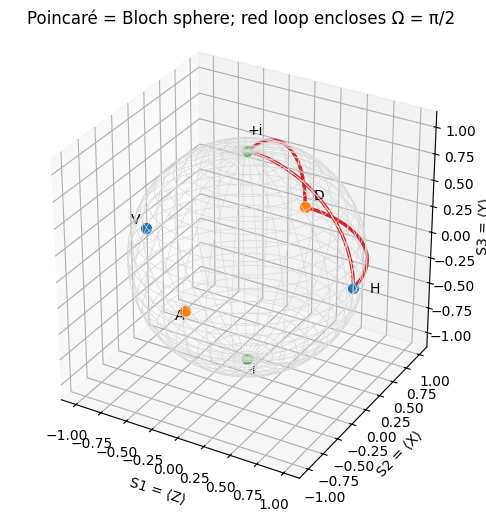

In [5]:
omega = solid_angle_octant()
t, p = sp.symbols("t p", positive=True)
display(Math(r"\Omega = \int_0^{\pi/2}\!\!\int_0^{\pi/2} \sin t\,dt\,dp = " + sp.latex(omega)))
g1 = pancharatnam_phase([numeric("H"), numeric("D"), numeric("+i")])
g2 = pancharatnam_phase([numeric("H"), numeric("+i"), numeric("D")])
print(f"phase of the loop H→D→+i→H: {g1:+.6f} rad;  reversed: {g2:+.6f} rad;  Ω/2 = {float(omega)/2:.6f}")
u = np.linspace(0, 2*np.pi, 60); v = np.linspace(0, np.pi, 30)
fig = plt.figure(figsize=(6, 6)); ax = fig.add_subplot(projection="3d")
ax.plot_wireframe(np.outer(np.cos(u), np.sin(v)), np.outer(np.sin(u), np.sin(v)), np.outer(np.ones_like(u), np.cos(v)), color="0.85", lw=0.5)
for k, col in zip(KETS, ("C0", "C0", "C1", "C1", "C2", "C2")):
    s = [float(c) for c in bloch_vector(KETS[k])["stokes"]]; ax.scatter(*s, color=col, s=50); ax.text(*(np.array(s)*1.15), k)
for a, b in (("H", "D"), ("D", "+i"), ("+i", "H")):
    pa = np.array([float(c) for c in bloch_vector(KETS[a])["stokes"]]); pb = np.array([float(c) for c in bloch_vector(KETS[b])["stokes"]])
    arc = np.array([np.cos(s)*pa + np.sin(s)*pb for s in np.linspace(0, np.pi/2, 30)]); ax.plot(*arc.T, "C3", lw=2.5)
ax.set(xlabel="S1 = ⟨Z⟩", ylabel="S2 = ⟨X⟩", zlabel="S3 = ⟨Y⟩", title="Poincaré = Bloch sphere; red loop encloses Ω = π/2")
ax.set_box_aspect((1, 1, 1)); plt.show()

Geometric phases are real and measurable (Pancharatnam 1956; Berry 1984). They're the same
mathematics as the Aharonov–Bohm effect in E&M and as geometric quantum gates in QIS.

# B5. A note on conventions

`dgs/jones_calculus.py`'s *docstring* says a quarter-wave plate is $\mathrm{diag}(1, -i)$ and calls
$(1, -i)/\sqrt2$ the $S_3 = +1$ pole. Its *code* gives $\mathrm{diag}(1, +i)$, and $S_3 = -1$ for that state.
The other modules that use it rely on the code's behavior, so this notebook follows the code, and
the tests pin it. Sign conventions for circular polarization genuinely differ between optics
textbooks, so always check which one a formula uses.

## Exercises
1. Show that HWP(θ) maps $|H\rangle$ to linear polarization at $2\theta$. Why is the factor 2 there?
2. Find wave-plate settings that implement Pauli $X$ and Pauli $Y$ (up to global phase).
3. Compute the geometric phase for the loop $|H\rangle \to |D\rangle \to |V\rangle \to |A\rangle \to |H\rangle$ along the equator. Explain the answer from the solid angle.
4. Two photons, one in each arm of a beam splitter, are a two-qubit system. Which notebook in the course map describes what happens when they meet?